In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
import os

In [3]:

def load_circle_window(path: str):
    """Return (t, ee_xy, gauss_xy) arrays trimmed to the circling phase."""
    d = np.load(path)
    t        = d['t']
    goal     = d['goal']      # (n, N_VC, 3)
    comp_pos = d['comp_pos']  # (n, N_VC, 3)

    # Circle starts when |gauss_goal_y| first exceeds 2 mm, ends when it last does
    gauss_goal_y = goal[:, 1, 1]
    mask = np.abs(gauss_goal_y) > 0.002
    idx_start = np.where(mask)[0][0]
    idx_end   = np.where(mask)[0][-1]

    sl = slice(idx_start, idx_end + 1)
    t_w        = t[sl] - t[idx_start]          # zero-based time
    ee_xy      = comp_pos[sl, 0, :2]           # (n, 2)  lin_seg3 end-effector
    gauss_xy   = goal[sl, 1, :2]               # (n, 2)  gaussian goal

    return t_w, ee_xy, gauss_xy


def make_segments(xy: np.ndarray):
    """Convert (n, 2) path into (n-1, 2, 2) line segments for LineCollection."""
    pts = xy.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)


def draw_panel(ax, t, ee_xy, gauss_xy, title: str, cmap_name='coolwarm'):
    cmap = plt.colormaps[cmap_name]
    norm = mcolors.Normalize(vmin=0, vmax=t[-1])

    # Reference circle
    theta = np.linspace(0, 2 * np.pi, 300)
    ax.plot(0.10 * np.cos(theta), 0.10 * np.sin(theta),
            '--', color='gray', linewidth=0.8, alpha=0.5, label='R=10 cm ref')

    # Origin
    ax.plot(0, 0, 'k+', markersize=8, markeredgewidth=1.5, label='Origin')

    # Gaussian goal path
    segs_g = make_segments(gauss_xy)
    lc_g = LineCollection(segs_g, cmap=cmap, norm=norm,
                          linewidth=1.0, alpha=0.45, zorder=2)
    lc_g.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_g)
    # ghost handle for legend
    ax.plot([], [], color=cmap(0.5), linewidth=1.0, alpha=0.55, label='Gauss goal')

    # End-effector path
    segs_e = make_segments(ee_xy)
    lc_e = LineCollection(segs_e, cmap=cmap, norm=norm,
                          linewidth=1.8, zorder=3)
    lc_e.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_e)
    ax.plot([], [], color=cmap(0.0), linewidth=1.8, label='EE start')
    ax.plot([], [], color=cmap(1.0), linewidth=1.8, label='EE end')

    ax.set_title(title)
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')
    ax.set_aspect('equal')
    ax.legend(loc='upper right', framealpha=0.9)
    ax.grid(GRID)

    lim = 0.16
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    return lc_e  # return for shared colorbar


Saved → outputs/moving_gauss/xy_circle_comparison.pdf


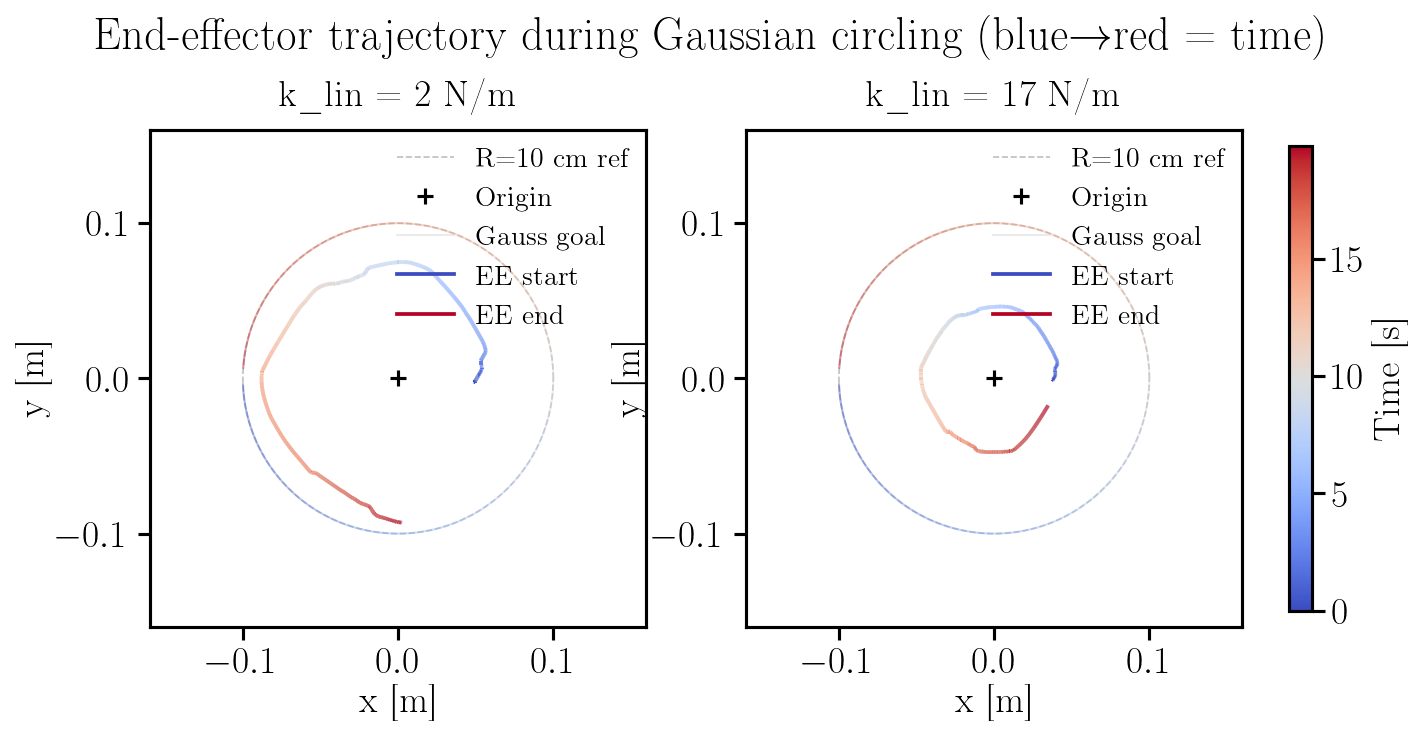

In [4]:

files = {
    'k_lin = 2 N/m':  os.path.join('outputs', 'moving_gauss', 'k5_moving_gauss.npz'),
    'k_lin = 17 N/m': os.path.join('outputs', 'moving_gauss', 'k50_moving_gauss.npz'),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('End-effector trajectory during Gaussian circling  (blue→red = time)')

last_lc = None
last_t  = None

for ax, (title, path) in zip(axes, files.items()):
    t, ee_xy, gauss_xy = load_circle_window(path)
    lc = draw_panel(ax, t, ee_xy, gauss_xy, title)
    last_lc = lc
    last_t  = t

# Shared colorbar (time axis)
cbar = fig.colorbar(last_lc, ax=axes, orientation='vertical',
                    fraction=0.02, pad=0.04, label='Time [s]')

out = os.path.join('outputs', 'moving_gauss', 'xy_circle_comparison.pdf')
fig.savefig(out)
print(f"Saved → {out}")
plt.show()
